<a href="https://colab.research.google.com/github/JFSS20000/07MIAR04/blob/main/07MIAR04_B_2026_Articulo_C1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Instalación de librerías

In [1]:
# Instalación de librerías
!pip install -q transformers accelerate bitsandbytes matplotlib seaborn torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.7 MB/s eta 0:00:00


## Carga del Modelo "Qwen" y Ejecución del Flujo de Trabajo

In [2]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

# -------------------------------------------------------------------
# 0. CONFIGURACIÓN Y CARGA DEL MODELO
# -------------------------------------------------------------------
# Se utiliza la versión de 14B de la familia Qwen.
model_id = "Qwen/Qwen2.5-14B-Instruct"

# Cuantización de 4 bits (NF4) indispensable para cargar 14B parámetros en T4 (15GB VRAM)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print(f"Cargando tokenizador y arquitectura de {model_id}...")
tokenizer = AutoTokenizer.from_pretrained(model_id)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    output_attentions=True,        # Requerido para capturar matrices de atención
    attn_implementation="eager",   # Fuerz el calculo explícito omitiendo optimizaciones como FlashAttention
    device_map="auto"
)


Cargando tokenizador y arquitectura de Qwen/Qwen2.5-14B-Instruct...


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

[transformers] The following generation flags are not valid and may be ignored: ['output_attentions']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/579 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

  #### 1. MODEL SUMMARY

In [3]:

# -------------------------------------------------------------------
# 1. MODEL SUMMARY
# -------------------------------------------------------------------
print("\n" + "="*50)
print("1. MODEL SUMMARY Y ESTRUCTURA DE CAPAS (Qwen2.5-14B)")
print("="*50)
print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nTotal de hiperparámetros (base): {total_params:,}")
print(f"Hiperparámetros entrenables (con cuantización 4-bit): {trainable_params:,}")



1. MODEL SUMMARY Y ESTRUCTURA DE CAPAS (Qwen2.5-14B)
Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(152064, 5120)
    (layers): ModuleList(
      (0-47): 48 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear4bit(in_features=5120, out_features=5120, bias=True)
          (k_proj): Linear4bit(in_features=5120, out_features=1024, bias=True)
          (v_proj): Linear4bit(in_features=5120, out_features=1024, bias=True)
          (o_proj): Linear4bit(in_features=5120, out_features=5120, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear4bit(in_features=5120, out_features=13824, bias=False)
          (up_proj): Linear4bit(in_features=5120, out_features=13824, bias=False)
          (down_proj): Linear4bit(in_features=13824, out_features=5120, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((5120,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((5

  #### 2. ANÁLISIS DE TENSORES: ENTRADA Y LOGITS DE SALIDA


=== 2. TENSOR DE ENTRADA Y LOGITS ===
Forma del Tensor de Entrada (input_ids): torch.Size([1, 15])
Valores del Tensor de Entrada (IDs): [[8747, 796, 446, 8360, 5690, 62379, 51503, 28294, 277, 32025, 65573, 3233, 266, 92773, 13]]

Forma del Tensor de Logits de Salida: torch.Size([1, 15, 152064])


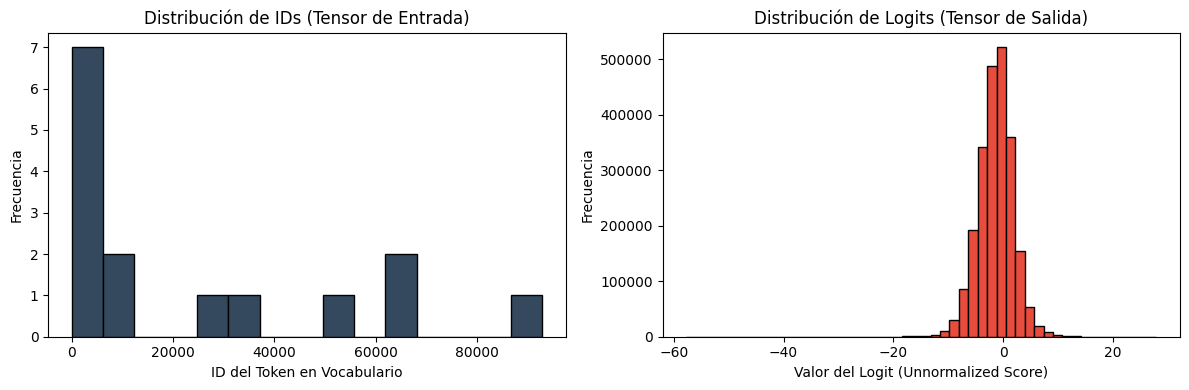

In [4]:
# -------------------------------------------------------------------
# 2. ANÁLISIS DE TENSORES: ENTRADA Y LOGITS DE SALIDA
# -------------------------------------------------------------------
print("\n=== 2. TENSOR DE ENTRADA Y LOGITS ===")
text_input = "La arquitectura Transformer permite procesar texto mediante autoatencion."
inputs = tokenizer(text_input, return_tensors="pt").to(model.device)

with torch.no_grad():
    outputs = model(**inputs)
    logits = outputs.logits  # [batch_size, sequence_length, vocab_size]

input_ids = inputs["input_ids"].cpu()
logits_cpu = logits.cpu().float()

print("Forma del Tensor de Entrada (input_ids):", input_ids.shape)
print("Valores del Tensor de Entrada (IDs):", input_ids.numpy().tolist())
print("\nForma del Tensor de Logits de Salida:", logits_cpu.shape)

# Graficar distribuciones de valores
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(input_ids.numpy().flatten(), bins=15, color='#34495e', edgecolor='black')
axes[0].set_title("Distribución de IDs (Tensor de Entrada)")
axes[0].set_xlabel("ID del Token en Vocabulario")
axes[0].set_ylabel("Frecuencia")

axes[1].hist(logits_cpu.numpy().flatten(), bins=50, color='#e74c3c', edgecolor='black')
axes[1].set_title("Distribución de Logits (Tensor de Salida)")
axes[1].set_xlabel("Valor del Logit (Unnormalized Score)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()



#### 3. MAPAS DE CALOR DE SELF-ATTENTION


=== 3. VISUALIZACIÓN DE AUTOATENCIÓN ===


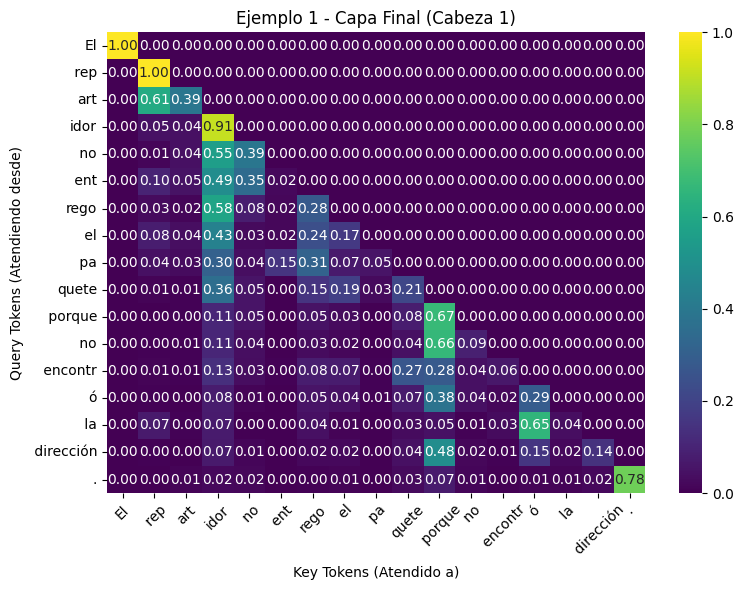

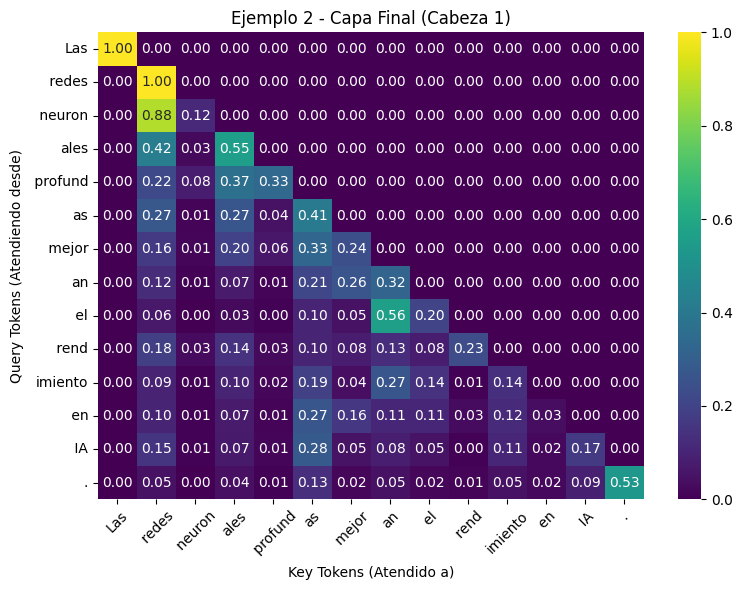

In [5]:
# -------------------------------------------------------------------
# 3. MAPAS DE CALOR DE SELF-ATTENTION
# -------------------------------------------------------------------
print("\n=== 3. VISUALIZACIÓN DE AUTOATENCIÓN ===")

def plot_qwen_attention(text, title_prefix=""):
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    tokens = [tokenizer.decode([token_id]) for token_id in inputs["input_ids"][0]]

    with torch.no_grad():
        out = model(**inputs, output_attentions=True)

    # Extraer matriz de atención de la última capa, cabeza 0: [seq_len, seq_len]
    attention_matrix = out.attentions[-1][0, 0].cpu().float().numpy()

    plt.figure(figsize=(8, 6))
    sns.heatmap(attention_matrix, xticklabels=tokens, yticklabels=tokens,
                cmap="viridis", annot=True, fmt=".2f", cbar=True)
    plt.title(f"{title_prefix} - Capa Final (Cabeza 1)")
    plt.xlabel("Key Tokens (Atendido a)")
    plt.ylabel("Query Tokens (Atendiendo desde)")
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Ejemplo 1
plot_qwen_attention("El repartidor no entrego el paquete porque no encontró la dirección.", "Ejemplo 1")

# Ejemplo 2
plot_qwen_attention("Las redes neuronales profundas mejoran el rendimiento en IA.", "Ejemplo 2")